# Rede de proteínas associadas à doença de Alzheimer (STRING)

**Autor:** _Edson Maciel de Barros Junior_

**Pergunta:** entre as proteínas associadas ao Alzheimer, quais ocupam posições estruturais críticas
(hubs, pontes entre módulos, núcleo denso) e seriam alvos candidatos a investigação?

**Modelagem:** nó = proteína; aresta = interação funcional do STRING; peso = *combined score* (0 a 1);
não dirigido. Ficam de fora: proteínas sem associação à doença, tipo de interação (física vs. funcional) e contexto tecidual.

**Como executar:** `pip install -r requirements.txt` e depois *Reiniciar e executar tudo*.
O notebook baixa os dados sozinho (CSV de genes + API do STRING) e salva tudo em `dados/`, `resultados/` e `figuras/`.

## 1. Configuração (semana 2: tipos de grafo e atributos)

In [1]:
import os
from io import StringIO
from itertools import combinations

import numpy as np
import pandas as pd
import requests
import networkx as nx
import matplotlib.pyplot as plt

# ---- parâmetros do projeto ----
URL_CSV = ("https://raw.githubusercontent.com/DevMacielJr/"
           "rede-proteinas-alzheimer/main/dados/genes_alzheimer.csv")
N_GENES = 200
LIMIARES = [400, 700, 900]      # escala 0-1000 do STRING (required_score)
LIMIAR_PRINCIPAL = 700          # limiar usado nas tabelas e na figura principal
GENES_REFERENCIA = ["APP", "APOE", "MAPT", "PSEN1"]

for pasta in ("dados", "resultados", "figuras"):
    os.makedirs(pasta, exist_ok=True)

## 2. Lista de genes (Open Targets, top 200 por score)

In [2]:
caminho_genes = "dados/genes_alzheimer.csv"
if not os.path.exists(caminho_genes):
    r = requests.get(URL_CSV, timeout=60)
    r.raise_for_status()
    with open(caminho_genes, "wb") as f:
        f.write(r.content)

genes_df = pd.read_csv(caminho_genes)
assert "symbol" in genes_df.columns, f"Colunas disponíveis: {genes_df.columns.tolist()}"

genes = (genes_df["symbol"].dropna().astype(str).str.strip()
         .loc[lambda s: s != ""].drop_duplicates().head(N_GENES).tolist())
print(len(genes), "genes selecionados:", genes[:15], "...")

200 genes selecionados: ['APP', 'PSEN1', 'PSEN2', 'APOE', 'ABCA7', 'SORL1', 'GRIN1', 'ADAM10', 'CDK5', 'GRIN3B', 'ACE', 'APH1B', 'ACHE', 'GRN', 'GRIN2B'] ...


## 3. Download da rede do STRING para cada limiar

In [3]:
def baixar_rede(genes, limiar):
    """Baixa (ou reutiliza do cache) as interações do STRING para um limiar."""
    caminho = f"dados/string_{limiar}.tsv"
    if not os.path.exists(caminho):
        r = requests.post(
            "https://string-db.org/api/tsv/network",
            data={"identifiers": "\r".join(genes), "species": 9606,
                  "required_score": limiar, "caller_identity": "projeto_grafos"},
            timeout=180)
        r.raise_for_status()
        if not r.text.strip():
            raise ValueError(f"STRING devolveu resposta vazia para o limiar {limiar}.")
        with open(caminho, "w", encoding="utf-8") as f:
            f.write(r.text)
    return pd.read_csv(caminho, sep="\t")

interacoes = {t: baixar_rede(genes, t) for t in LIMIARES}
for t, d in interacoes.items():
    print(f"limiar {t}: {len(d)} interações")

limiar 400: 1231 interações
limiar 700: 584 interações
limiar 900: 379 interações


## 4. Construção dos grafos (semana 2)

O `score` do STRING na resposta da API vai de **0 a 1** (só o parâmetro `required_score` usa 0 a 1000).
Para a betweenness, que minimiza custo, definimos `dist = 1 - score` (mais confiança = aresta mais "curta").

In [4]:
def construir_grafo(df):
    d = df[["preferredName_A", "preferredName_B", "score"]].copy()
    d["score"] = pd.to_numeric(d["score"], errors="coerce")
    d = d.dropna()
    G = nx.from_pandas_edgelist(d, "preferredName_A", "preferredName_B",
                                edge_attr="score", create_using=nx.Graph())
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    assert 0 < d["score"].max() <= 1.0, "score fora da escala 0-1: verifique a resposta da API"
    for _, _, a in G.edges(data=True):
        a["dist"] = 1 - a["score"] + 1e-3   # custo da aresta (evita distância zero)
    return G

## 5. Métricas por rede

- grau e densidade (semana 2)
- componentes conexas e GCC (semana 4)
- betweenness (ponderada por `dist`), eigenvector (ponderado por `score`) e clustering (semana 4)
- core number (semana 5)

Betweenness e eigenvector são calculados na maior componente conexa (GCC); proteínas fora dela recebem 0.

In [5]:
def analisar_rede(df, limiar):
    G = construir_grafo(df)
    comps = list(nx.connected_components(G))
    gcc = G.subgraph(max(comps, key=len)).copy()

    btw = nx.betweenness_centrality(gcc, weight="dist")
    try:
        eig = nx.eigenvector_centrality(gcc, weight="score", max_iter=5000, tol=1e-8)
    except nx.PowerIterationFailedConvergence:
        eig = {n: np.nan for n in gcc}
    clu = nx.clustering(G)
    core = nx.core_number(G)

    tabela = pd.DataFrame({
        "protein": list(G.nodes()),
        "degree": [G.degree(n) for n in G],
        "betweenness": [btw.get(n, 0.0) for n in G],
        "eigenvector": [eig.get(n, 0.0) for n in G],
        "clustering": [clu[n] for n in G],
        "core_number": [core[n] for n in G],
    })
    resumo = {
        "limiar": limiar,
        "nos": G.number_of_nodes(),
        "genes_fora_da_rede": len(genes) - G.number_of_nodes(),
        "arestas": G.number_of_edges(),
        "densidade": nx.density(G),
        "componentes": len(comps),
        "nos_gcc": gcc.number_of_nodes(),
        "fracao_gcc": gcc.number_of_nodes() / G.number_of_nodes(),
        "max_core": max(core.values()),
    }
    return G, tabela, resumo

grafos, tabelas, resumos = {}, {}, []
for t, d in interacoes.items():
    grafos[t], tabelas[t], r = analisar_rede(d, t)
    resumos.append(r)

resumo_redes = pd.DataFrame(resumos)
resumo_redes

,limiar,nos,genes_fora_da_rede,arestas,densidade,componentes,nos_gcc,fracao_gcc,max_core
0,400,194,6,1231,0.065755,1,194,1.000000,16
1,700,176,24,584,0.037922,4,166,0.943182,16
2,900,148,52,379,0.034841,13,100,0.675676,15


## 6. Distribuição de grau (semana 2): escala linear e log-log

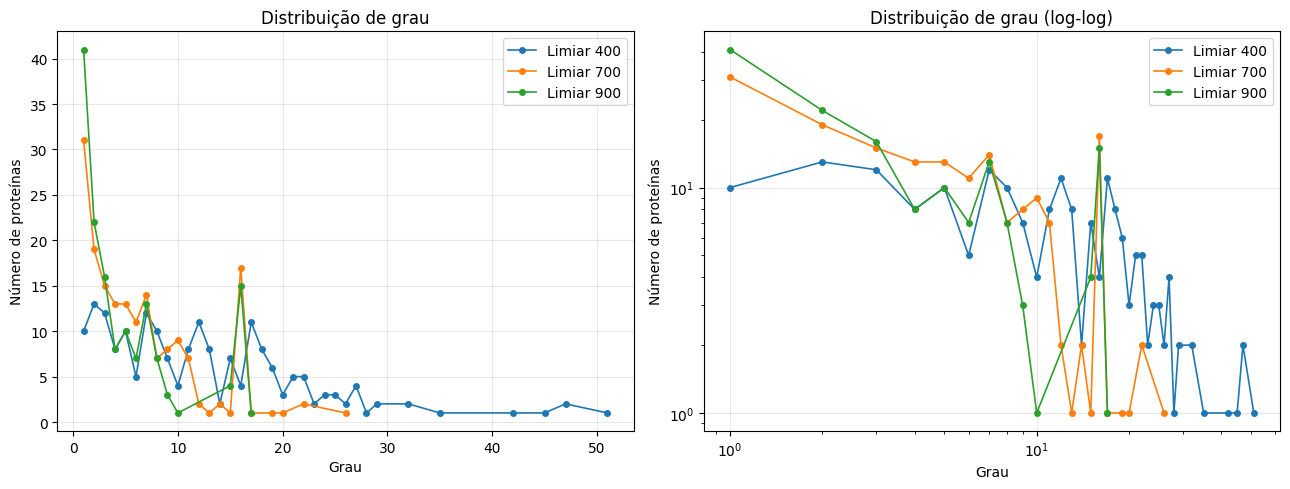

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for t, G in grafos.items():
    dist = pd.Series([g for _, g in G.degree()]).value_counts().sort_index()
    for a in ax:
        a.plot(dist.index, dist.values, marker="o", ms=4, lw=1.2, label=f"Limiar {t}")
ax[0].set_title("Distribuição de grau")
ax[1].set_title("Distribuição de grau (log-log)")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
for a in ax:
    a.set_xlabel("Grau"); a.set_ylabel("Número de proteínas")
    a.grid(alpha=0.3); a.legend()
plt.tight_layout()
plt.savefig("figuras/distribuicao_grau.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Top 10 por métrica no limiar principal

In [7]:
METRICAS = ["degree", "betweenness", "eigenvector", "clustering", "core_number"]
tab = tabelas[LIMIAR_PRINCIPAL]

top10 = pd.concat({
    m: tab.sort_values([m, "protein"], ascending=[False, True])
          .head(10)["protein"].reset_index(drop=True)
    for m in METRICAS}, axis=1)
top10.index = range(1, 11)
print(f"Top 10 por métrica, limiar {LIMIAR_PRINCIPAL}")
top10

Top 10 por métrica, limiar 700


,degree,betweenness,eigenvector,clustering,core_number
1,TP53,TP53,NDUFS5,ADRA2B,COX7C
2,APP,CSNK1A1,NDUFB7,ADRA2C,NDUFA5
3,EGFR,XPO1,NDUFA6,APH1B,NDUFA6
4,APOE,APP,NDUFB9,ATP1A1,NDUFA8
5,PICALM,LTV1,NDUFS2,ATP6V1C1,NDUFA9
6,NDUFS5,GSK3B,NDUFV2,BCHE,NDUFAB1
7,COX7C,PSEN1,NDUFS8,BMP2K,NDUFB7
8,DHX15,DIMT1,NDUFA8,COPZ1,NDUFB9
9,NDUFA5,NOC4L,NDUFV1,COX7C,NDUFC1
10,NDUFA6,DHX15,NDUFA5,GBF1,NDUFC2


### Correlação entre métricas (Spearman): hubs e pontes são as mesmas proteínas?

In [8]:
correlacao = tab[METRICAS].corr(method="spearman").round(2)
correlacao

,degree,betweenness,eigenvector,clustering,core_number
degree,1.00,0.55,0.66,0.52,0.93
betweenness,0.55,1.00,0.33,0.04,0.38
eigenvector,0.66,0.33,1.00,0.36,0.66
clustering,0.52,0.04,0.36,1.00,0.69
core_number,0.93,0.38,0.66,0.69,1.00


### Hubs (grau) × pontes (betweenness), top 10, em cada limiar

In [9]:
linhas = []
for t, tb in tabelas.items():
    hubs = set(tb.nlargest(10, "degree")["protein"])
    pontes = set(tb.nlargest(10, "betweenness")["protein"])
    linhas.append({"limiar": t, "em_comum": len(hubs & pontes),
                   "proteinas_em_comum": ", ".join(sorted(hubs & pontes))})
hubs_pontes = pd.DataFrame(linhas)
hubs_pontes

,limiar,em_comum,proteinas_em_comum
0,400,5,"APP, EGFR, GSK3B, PSEN1, TP53"
1,700,3,"APP, DHX15, TP53"
2,900,1,TP53


## 8. Robustez ao limiar de confiança (Jaccard entre top 10)

In [10]:
def top_n(tb, metrica, n=10):
    return set(tb.sort_values([metrica, "protein"], ascending=[False, True])
                 .head(n)["protein"])

linhas = []
for metrica in ("betweenness", "degree"):
    for a, b in combinations(LIMIARES, 2):
        A, B = top_n(tabelas[a], metrica), top_n(tabelas[b], metrica)
        linhas.append({"metrica": metrica, "limiar_a": a, "limiar_b": b,
                       "em_comum": len(A & B), "jaccard": round(len(A & B) / len(A | B), 2),
                       "nomes_em_comum": ", ".join(sorted(A & B))})
robustez = pd.DataFrame(linhas)
display(robustez)

nos_tres = set.intersection(*[top_n(tabelas[t], "betweenness") for t in LIMIARES])
print("Top 10 de betweenness presentes nos três limiares:", sorted(nos_tres))

,metrica,limiar_a,limiar_b,em_comum,jaccard,nomes_em_comum
0,betweenness,400,700,8,0.67,"APP, CSNK1A1, DIMT1, GSK3B, LTV1, PSEN1, TP53,..."
1,betweenness,400,900,10,1.00,"APP, CDK1, CSNK1A1, DIMT1, EGFR, GSK3B, LTV1, ..."
2,betweenness,700,900,8,0.67,"APP, CSNK1A1, DIMT1, GSK3B, LTV1, PSEN1, TP53,..."
3,degree,400,700,4,0.25,"APOE, APP, EGFR, TP53"
4,degree,400,900,1,0.05,TP53
5,degree,700,900,3,0.18,"NDUFA5, NDUFA6, TP53"


Top 10 de betweenness presentes nos três limiares: ['APP', 'CSNK1A1', 'DIMT1', 'GSK3B', 'LTV1', 'PSEN1', 'TP53', 'XPO1']


## 9. Validação e viés de pesquisa

Posição (1 = mais central) dos genes clássicos do Alzheimer em cada limiar.
Genes muito estudados têm mais interações no STRING, então grau alto pode refletir popularidade, não importância biológica.

In [11]:
linhas = []
for g in GENES_REFERENCIA:
    linha = {"gene": g}
    for t, tb in tabelas.items():
        for m in ("degree", "betweenness", "core_number"):
            rank = tb[m].rank(ascending=False, method="min")
            linha[f"{m}_{t}"] = int(rank[tb["protein"] == g].iloc[0]) if g in set(tb["protein"]) else None
    linhas.append(linha)
validacao = pd.DataFrame(linhas)
validacao

,gene,degree_400,betweenness_400,core_number_400,degree_700,betweenness_700,core_number_700,degree_900,betweenness_900,core_number_900
0,APP,5.0,5.0,18.0,2.0,4.0,26.0,17.0,9.0,39.0
1,APOE,2.0,16.0,18.0,4.0,18.0,26.0,22.0,16.0,55.0
2,MAPT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,PSEN1,7.0,3.0,18.0,27.0,7.0,26.0,32.0,8.0,55.0


## 10. Figuras principais

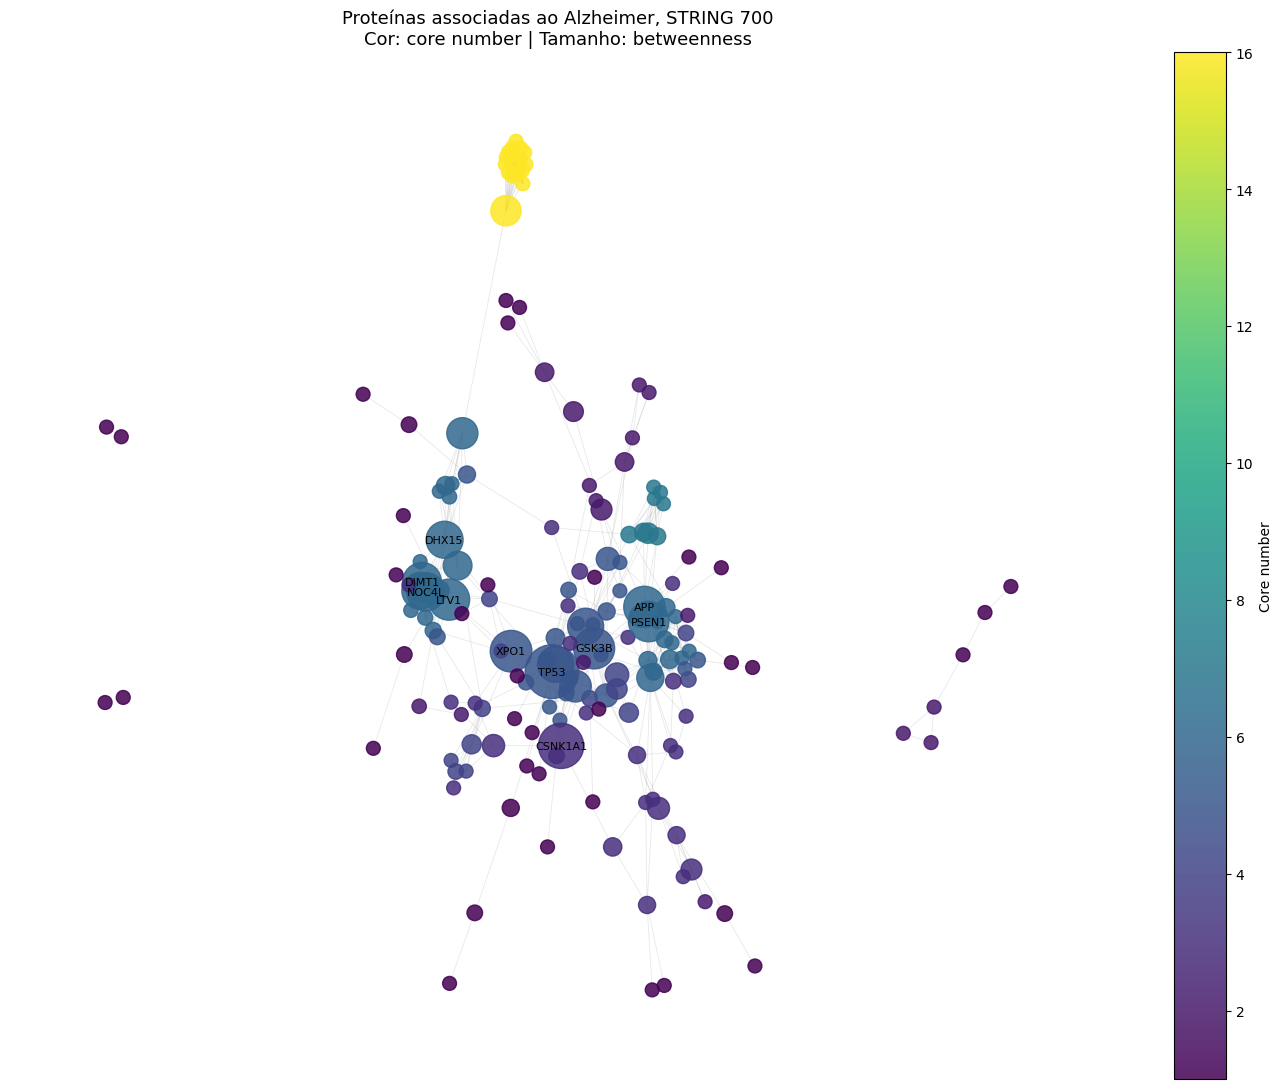

In [12]:
G = grafos[LIMIAR_PRINCIPAL]
tb = tab.set_index("protein")
btw = tb.loc[list(G.nodes()), "betweenness"].values
tamanhos = 100 + 1400 * btw / btw.max() if btw.max() > 0 else 100
pos = nx.spring_layout(G, seed=42, weight="score")

fig, ax = plt.subplots(figsize=(14, 11))
nos = nx.draw_networkx_nodes(G, pos, node_color=tb.loc[list(G.nodes()), "core_number"],
                             node_size=tamanhos, cmap=plt.cm.viridis, alpha=0.85, ax=ax)
nx.draw_networkx_edges(G, pos, alpha=0.18, width=0.6, edge_color="gray", ax=ax)
nx.draw_networkx_labels(G, pos, labels={n: n for n in top_n(tab, "betweenness")},
                        font_size=8, ax=ax)
fig.colorbar(nos, ax=ax, label="Core number")
ax.set_title(f"Proteínas associadas ao Alzheimer, STRING {LIMIAR_PRINCIPAL}\n"
             "Cor: core number | Tamanho: betweenness", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.savefig(f"figuras/grafo_string_{LIMIAR_PRINCIPAL}.png", dpi=200, bbox_inches="tight")
plt.show()

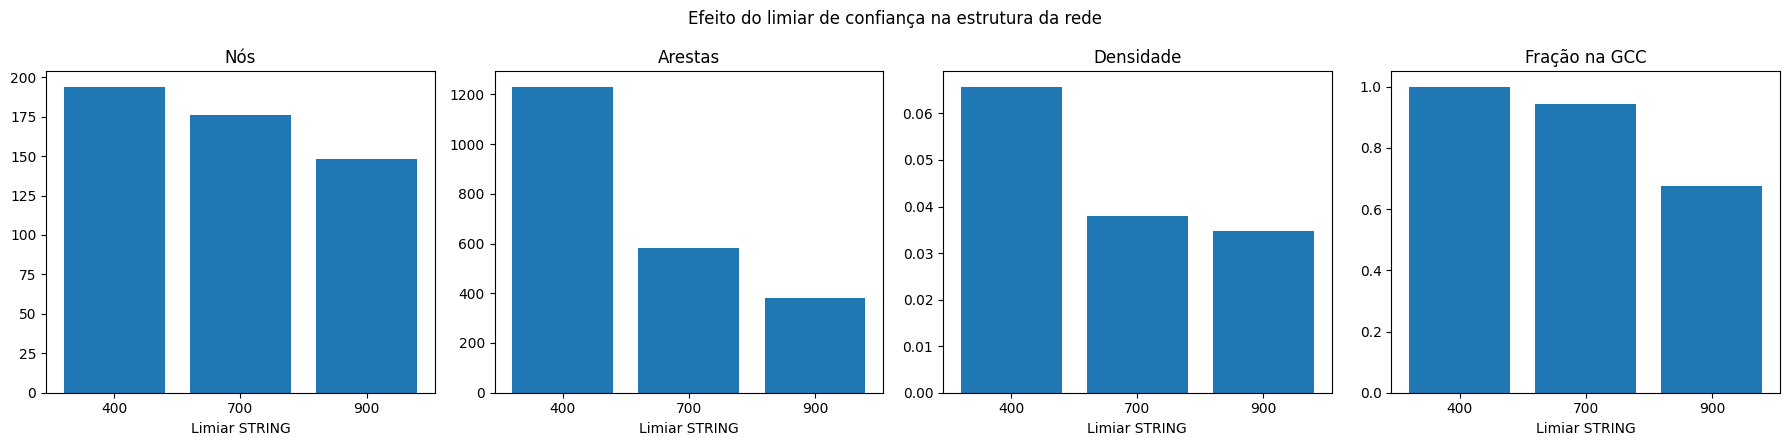

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
x = resumo_redes["limiar"].astype(str)
for a, col, tit in zip(ax, ["nos", "arestas", "densidade", "fracao_gcc"],
                       ["Nós", "Arestas", "Densidade", "Fração na GCC"]):
    a.bar(x, resumo_redes[col]); a.set_title(tit); a.set_xlabel("Limiar STRING")
fig.suptitle("Efeito do limiar de confiança na estrutura da rede")
plt.tight_layout()
plt.savefig("figuras/comparacao_limiares.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Exportar resultados

In [ ]:
for t, tb in tabelas.items():
    tb.to_csv(f"resultados/metricas_string_{t}.csv", index=False)
resumo_redes.to_csv("resultados/resumo_redes.csv", index=False)
correlacao.to_csv("resultados/correlacao_metricas.csv")
hubs_pontes.to_csv("resultados/hubs_vs_pontes.csv", index=False)
robustez.to_csv("resultados/robustez_limiar.csv", index=False)
validacao.to_csv("resultados/validacao_genes_referencia.csv", index=False)
print(sorted(os.listdir("resultados")))